# 03. CAPM, Dimson beta and R-squared by regime

**Purpose.** Measure how much of each bank's daily excess return is explained by the market (IHSG), and whether that exposure changed across the interest-rate regimes. This covers the main research question on variance explained by market exposure and the two hypotheses in `metric_definitions.md`.

**Metrics covered.**
- **M7 CAPM.** `e_bank = alpha + beta * e_IHSG`, ordinary least squares, per bank, for the full period and for R1, R2 and R3. Standard errors are HC3 heteroskedasticity-robust. The Ljung-Box test on the residuals is reported.
- **H1.** A t-test of `beta = 1` for each bank and period (HC3 standard errors, t distribution).
- **H2.** R-squared per period with a stationary block-bootstrap interval, and bootstrap intervals for the differences R1 - R2, R2 - R3 and R1 - R3.
- **M8 Dimson beta.** Sum of the slopes on the market return one day earlier, the same day and one day later, as a check on non-synchronous trading.

**How to run.** Select the project `.venv` as the kernel, then use *Restart* and *Run All*. The notebook asks for the PostgreSQL user and password at the first data cell. It only reads from the database. The bootstrap step takes roughly a minute. Tables are saved as CSV files in `reports/` (ignored by git).

**Read these before using the numbers.**
- The Stub (from 20 May 2026) is excluded from H1 and H2: 90 days are too few.
- The three banks are a large part of the IHSG itself, so the market exposure is partly mechanical. A high R-squared does not show that the market drives the bank.
- Twelve t-tests are run for H1 (three banks, four periods). The p-values are not adjusted for multiple testing, so treat a single p-value near 0.05 with caution.
- The regimes have unequal lengths (399, 499 and 393 return days), which affects the width of every interval.
- Excess returns use the policy rate divided by 252, and returns are price returns (dividends excluded).
- Everything is in-sample and descriptive. A regression coefficient is not causal.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
try:
    import db_access
    import metrics
    import statsmodels.api as sm
    from statsmodels.stats.diagnostic import acorr_ljungbox
except ImportError as exc:
    raise ImportError(
        f"{exc}\nThis kernel is {sys.executable}. Select the project .venv kernel "
        "(top right of the notebook, Select Kernel > Python Environments > .venv), then Restart and Run All."
    ) from exc

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
print("project root:", ROOT)

project root: d:\Data Analyst\Portfolio


## 1. Load the data

Three reads, all `SELECT` only. Prices and the policy rate are used to rebuild the excess returns in Python (as in notebook 02). `load_capm_sql` runs the same regressions inside PostgreSQL (`regr_slope`, `regr_intercept`, `regr_r2`) and is used only to cross-check the Python results.

In [2]:
conn = db_access.connect()
try:
    prices = db_access.load_prices(conn)
    sql = db_access.load_excess_returns(conn)
    capm_sql = db_access.load_capm_sql(conn)
finally:
    conn.close()

print("prices rows:", len(prices), "| SQL view rows:", len(sql), "| SQL CAPM rows:", len(capm_sql))

prices rows: 5536 | SQL view rows: 5524 | SQL CAPM rows: 15


## 2. Settings and small helpers

The bootstrap settings follow docs/metric_definitions.md (design decision 3): 10,000 resamples, mean block length 10 days, a fixed seed, with block lengths 5 and 21 as sensitivity. Each period gets its own seed so that the resamples of different periods are independent, which the difference intervals rely on. Within a period the same resampled dates are used for all three banks.

In [3]:
BANKS = ["BBCA", "BBRI", "BMRI"]
MARKET = "IHSG"
TICKERS = BANKS + [MARKET]
FIRST_RETURN_DAY = pd.Timestamp("2021-01-04")
EXPECTED_DAYS = 1381
REGIME_DAYS = {"R1": 399, "R2": 499, "R3": 393, "Stub": 90}
PERIODS = ["Full", "R1", "R2", "R3"]            # the Stub is excluded from H1 and H2
PAIRS = [("R1", "R2"), ("R2", "R3"), ("R1", "R3")]

N_BOOT = 10_000
BLOCK = 10
SENSITIVITY_BLOCKS = (5, 21)
SEED = 20260101
LEVEL = 0.95
LB_LAGS = (10, 20)
RET_TOL = 1e-12
SQL_TOL = 1e-8

COLORS = {"BBCA": "#2a78d6", "BBRI": "#eb6834", "BMRI": "#1baf7a", "IHSG": "#52514e"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d3"

results = []


def check(name, ok, detail=""):
    results.append(bool(ok))
    print(f"{'PASS' if ok else 'FAIL'}  {name}" + (f"  [{detail}]" if detail else ""))


def tidy(ax, title, ylabel):
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_ylabel(ylabel, color=MUTED)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED)


def legend_outside(ax):
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0), labelcolor=MUTED)

## 3. Excess returns and periods

Same construction as notebook 02: simple returns from `close`, daily risk-free rate = policy rate / 100 / 252, excess return = return minus that rate. `period_days` lists the return days in each period.

`cluster` marks the days on which at least three of the four instruments moved by more than 5%. These are the market-wide shock days (they include 2025-04-08 and 2026-06-09). They are used in the sensitivity at the end of the notebook.

In [4]:
close = db_access.to_wide(prices, "close")[TICKERS]
ret = metrics.simple_returns(close, FIRST_RETURN_DAY)

rate = sql.drop_duplicates("trade_date").set_index("trade_date")["rate_pct"].sort_index()
excess = metrics.excess_return(ret, metrics.daily_risk_free(rate))

labels = metrics.assign_regime(ret.index)
period_days = {"Full": ret.index}
period_days.update({name: ret.index[labels == name] for name in REGIME_DAYS})
cluster = (ret.abs() > 0.05).sum(axis=1) >= 3

sql_excess = db_access.to_wide(sql, "excess_close")[TICKERS]
check("return dates equal SQL view dates", ret.index.equals(sql_excess.index), f"{len(ret)} days")
check(f"{EXPECTED_DAYS} return days, no missing values", len(ret) == EXPECTED_DAYS and not excess.isna().any().any())
check("excess returns equal the SQL view", (excess - sql_excess).abs().max().max() < RET_TOL)
check("regime day counts", all(len(period_days[r]) == n for r, n in REGIME_DAYS.items()), str(REGIME_DAYS))
print("market-wide shock days (at least 3 of 4 instruments beyond 5%):", int(cluster.sum()))

PASS  return dates equal SQL view dates  [1381 days]
PASS  1381 return days, no missing values
PASS  excess returns equal the SQL view
PASS  regime day counts  [{'R1': 399, 'R2': 499, 'R3': 393, 'Stub': 90}]
market-wide shock days (at least 3 of 4 instruments beyond 5%): 6


## 4. M7 CAPM regressions and H1

One regression per bank and period: `e_bank = alpha + beta * e_IHSG + error`. The table gives:
- `alpha_ann_pct`: the daily intercept times 252, in percent (descriptive; the p-value `alpha_p` uses HC3 errors).
- `beta`, its HC3 standard error, and the 95% interval from the t distribution.
- `t_vs_1` and `p_vs_1`: the H1 test of `beta = 1`.
- `r2`: the share of the bank's return variance explained by the IHSG in this sample.
- `lb_p10`, `lb_p20`: Ljung-Box p-values for residual autocorrelation at 10 and 20 lags. A small value means the residuals are autocorrelated; HC3 errors do not correct for that, so a small value is a warning about the precision of the standard errors.

In [5]:
def fit_capm(y, x):
    """OLS of y on x with an intercept; HC3 robust errors and the t distribution."""
    return sm.OLS(y, sm.add_constant(x.rename("mkt"))).fit(cov_type="HC3", use_t=True)


def capm_row(period, ticker, days):
    res = fit_capm(excess.loc[days, ticker], excess.loc[days, MARKET])
    ci = res.conf_int().loc["mkt"]
    h1 = res.t_test("mkt = 1")
    lb = acorr_ljungbox(res.resid, lags=list(LB_LAGS), return_df=True)
    return {
        "period": period, "ticker": ticker, "n": int(res.nobs),
        "alpha": res.params["const"], "alpha_ann_pct": 100 * 252 * res.params["const"], "alpha_p": res.pvalues["const"],
        "beta": res.params["mkt"], "beta_se": res.bse["mkt"], "beta_ci_low": ci.iloc[0], "beta_ci_high": ci.iloc[1],
        "t_vs_1": float(np.squeeze(h1.tvalue)), "p_vs_1": float(np.squeeze(h1.pvalue)),
        "r2": res.rsquared, **{f"lb_p{lag}": lb.loc[lag, "lb_pvalue"] for lag in LB_LAGS},
    }


capm_table = pd.DataFrame(
    [capm_row(p, t, period_days[p]) for p in PERIODS for t in BANKS]
).set_index(["period", "ticker"])
capm_table.round(4)

n   alpha  alpha_ann_pct  alpha_p    beta  beta_se  beta_ci_low  beta_ci_high  t_vs_1  p_vs_1      r2  lb_p10  lb_p20
period ticker                                                                                                                          
Full   BBCA    1381 -0.0000        -0.6595   0.9383  0.9365   0.0475       0.8432        1.0297 -1.3366  0.1816  0.3769  0.0106  0.0622
       BBRI    1381 -0.0000        -0.2329   0.9810  1.1404   0.0488       1.0446        1.2362  2.8743  0.0041  0.4045  0.0006  0.0008
       BMRI    1381  0.0003         7.9450   0.4364  1.1693   0.0526       1.0662        1.2725  3.2206  0.0013  0.3973  0.2170  0.4620
R1     BBCA     399  0.0000         0.8982   0.9506  1.0566   0.0882       0.8832        1.2301  0.6418  0.5214  0.3951  0.0088  0.0065
       BBRI     399 -0.0001        -2.9240   0.8717  1.3380   0.0896       1.1618        1.5142  3.7708  0.0002  0.4021  0.2153  0.3186
       BMRI     399  0.0003         8.5714   0.6372  1.3168   0.0980       1.1240        1.5096  3.2312  0.0013  0.3909  0.1339  0.1994
R2     BBCA     499  0.0004        10.1657   0.3939  0.9550   0.0774       0.8030        1.1071 -0.5809  0.5616  0.2763  0.0159  0.1017
       BBRI     499  0.0003         8.4854   0.5431  1.3557   0.0933       1.1725        1.5389  3.8141  0.0002  0.3597  0.0067  0.0667
       BMRI     499  0.0010        26.0745   0.0822  1.4452   0.1052       1.2384        1.6519  4.2311  0.0000  0.3564  0.4891  0.5475
R3     BBCA     393 -0.0010       -24.1644   0.1844  0.8242   0.0790       0.6688        0.9796 -2.2247  0.0267  0.3691  0.1993  0.4639
       BBRI     393 -0.0007       -18.2087   0.3891  1.0379   0.0851       0.8706        1.2052  0.4454  0.6563  0.4135  0.4056  0.2395
       BMRI     393 -0.0008       -19.2556   0.3923  1.0598   0.0904       0.8821        1.2374  0.6613  0.5088  0.3944  0.5382  0.9029

### Validation of M7

Three independent checks: a hand calculation with `cov / var` in numpy, the `metrics.capm` function, and the regressions run inside PostgreSQL. The SQL match tolerance is 1e-8.

In [6]:
manual = {}
for (p, t) in capm_table.index:
    y, x = excess.loc[period_days[p], t].to_numpy(), excess.loc[period_days[p], MARKET].to_numpy()
    b = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
    manual[(p, t)] = (b, y.mean() - b * x.mean(), np.corrcoef(x, y)[0, 1] ** 2)
manual = pd.DataFrame(manual, index=["beta", "alpha", "r2"]).T.rename_axis(["period", "ticker"])
d_manual = (manual - capm_table[["beta", "alpha", "r2"]]).abs().max().max()
check("statsmodels equals the manual cov/var calculation", d_manual < 1e-10, f"max abs diff {d_manual:.2e}")

fun = pd.DataFrame({k: metrics.capm(excess.loc[period_days[k[0]], k[1]], excess.loc[period_days[k[0]], MARKET])
                    for k in capm_table.index}).T.rename_axis(["period", "ticker"])
check("metrics.capm equals statsmodels", (fun[["beta", "alpha", "r2"]] - capm_table[["beta", "alpha", "r2"]]).abs().max().max() < 1e-10)

sqlc = capm_sql.rename(columns={"n": "n_sql", "beta": "beta_sql", "alpha": "alpha_sql", "r2": "r2_sql"}).set_index(["period", "ticker"])
joined = capm_table.join(sqlc, how="left")
d_sql = max((joined[c] - joined[f"{c}_sql"]).abs().max() for c in ("beta", "alpha", "r2"))
check("Python CAPM equals the SQL regr_* results", d_sql < SQL_TOL and (joined["n"] == joined["n_sql"]).all(), f"max abs diff {d_sql:.2e}")

PASS  statsmodels equals the manual cov/var calculation  [max abs diff 8.88e-16]
PASS  metrics.capm equals statsmodels
PASS  Python CAPM equals the SQL regr_* results  [max abs diff 2.44e-15]


### H1: is beta different from 1?

Each dot is a bank's beta with its 95% HC3 interval. The dashed line is beta = 1. An interval that excludes 1 corresponds to a p-value below 0.05 in the table. Intervals are wider in the shorter regimes.

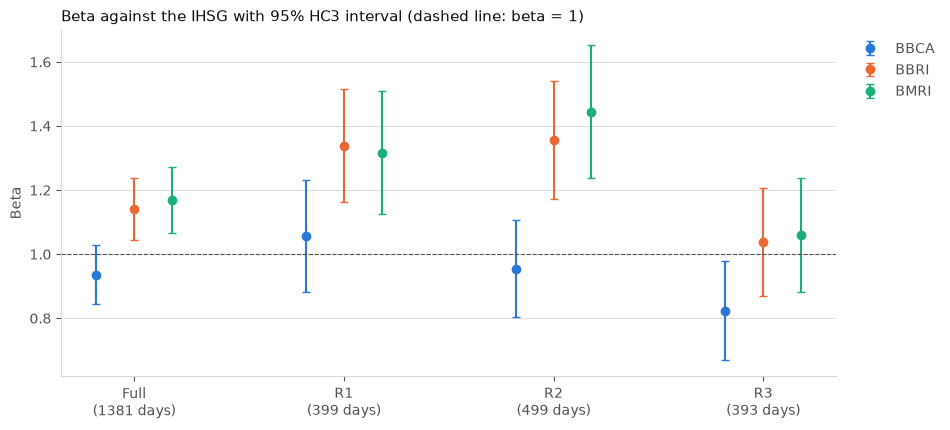

In [7]:
def dot_whisker(ax, table, value, low, high, offsets=(-1, 0, 1), spacing=0.18):
    for j, t in zip(offsets, BANKS):
        x = np.arange(len(PERIODS)) + j * spacing
        v = np.array([table.loc[(p, t), value] for p in PERIODS])
        lo = np.array([table.loc[(p, t), low] for p in PERIODS])
        hi = np.array([table.loc[(p, t), high] for p in PERIODS])
        ax.errorbar(x, v, yerr=[v - lo, hi - v], fmt="o", ms=6, lw=1.5, capsize=3, color=COLORS[t], label=t)
    ax.set_xticks(range(len(PERIODS)))
    ax.set_xticklabels([f"{p}\n({len(period_days[p])} days)" for p in PERIODS])


fig, ax = plt.subplots(figsize=(10, 4.5))
dot_whisker(ax, capm_table, "beta", "beta_ci_low", "beta_ci_high")
ax.axhline(1, color=MUTED, lw=0.8, ls="--")
tidy(ax, "Beta against the IHSG with 95% HC3 interval (dashed line: beta = 1)", "Beta")
legend_outside(ax)
plt.show()

### H1 robustness: Newey-West standard errors

HC3 standard errors allow for changing variance but not for autocorrelation in the residuals. The Ljung-Box test above flags some regressions (for example BBCA in R1 and R2, BBRI in the full period and R2), so the same t-test of `beta = 1` is repeated with Newey-West (HAC) standard errors, which allow for both (Newey and West, 1987). The kernel is Bartlett, with two choices of lag length: the common rule `floor(4 * (n / 100) ^ (2 / 9))` (Newey and West, 1994), which gives 5 to 7 lags here, and a fixed 10 lags to match the Ljung-Box setting. The beta estimates do not change; only the standard errors and p-values do.

`decision_flips` is True when the verdict at the 5% level (reject or not reject `beta = 1`) differs between HC3 and either HAC choice. The p-values are still unadjusted for the twelve tests.

In [8]:
def hac_lags(n):
    return int(np.floor(4 * (n / 100) ** (2 / 9)))


def fit_hac(y, x, lags):
    # OLS with Newey-West (Bartlett kernel) standard errors and the t distribution
    return sm.OLS(y, sm.add_constant(x.rename("mkt"))).fit(cov_type="HAC", cov_kwds={"maxlags": lags}, use_t=True)


def newey_west_se(y, x, lags):
    # independent hand calculation of the Newey-West standard errors (intercept, slope)
    X = np.column_stack([np.ones(len(x)), x])
    u = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
    Xu = X * u[:, None]
    S = Xu.T @ Xu
    for j in range(1, lags + 1):
        G = Xu[j:].T @ Xu[:-j]
        S += (1 - j / (lags + 1)) * (G + G.T)
    bread = np.linalg.inv(X.T @ X)
    return np.sqrt(np.diag(bread @ S @ bread))


rows = []
for (p, t) in capm_table.index:
    y, x = excess.loc[period_days[p], t], excess.loc[period_days[p], MARKET]
    row = {"period": p, "ticker": t, "n": len(y), "beta": capm_table.loc[(p, t), "beta"],
           "se_hc3": capm_table.loc[(p, t), "beta_se"], "p_hc3": capm_table.loc[(p, t), "p_vs_1"],
           "lb_p10": capm_table.loc[(p, t), "lb_p10"]}
    for label, lags in (("auto", hac_lags(len(y))), ("10", 10)):
        res = fit_hac(y, x, lags)
        row[f"lags_{label}"] = lags
        row[f"se_hac_{label}"] = res.bse["mkt"]
        row[f"p_hac_{label}"] = float(np.squeeze(res.t_test("mkt = 1").pvalue))
        row[f"beta_{label}"] = res.params["mkt"]
    row["decision_flips"] = any((row["p_hc3"] < 0.05) != (row[f"p_hac_{k}"] < 0.05) for k in ("auto", "10"))
    rows.append(row)
hac = pd.DataFrame(rows).set_index(["period", "ticker"])
hac["se_ratio_auto"] = hac["se_hac_auto"] / hac["se_hc3"]
print("rows where the 5% verdict differs between HC3 and HAC:", int(hac["decision_flips"].sum()), "of", len(hac))
hac.drop(columns=["beta_auto", "beta_10"]).round(4)

rows where the 5% verdict differs between HC3 and HAC: 0 of 12


n    beta  se_hc3   p_hc3  lb_p10  lags_auto  se_hac_auto  p_hac_auto  lags_10  se_hac_10  p_hac_10  decision_flips  se_ratio_auto
period ticker                                                                                                                                       
Full   BBCA    1381  0.9365  0.0475  0.1816  0.0106          7       0.0533      0.2334       10     0.0549    0.2479           False         1.1211
       BBRI    1381  1.1404  0.0488  0.0041  0.0006          7       0.0620      0.0237       10     0.0648    0.0306           False         1.2693
       BMRI    1381  1.1693  0.0526  0.0013  0.2170          7       0.0597      0.0046       10     0.0620    0.0064           False         1.1348
R1     BBCA     399  1.0566  0.0882  0.5214  0.0088          5       0.0972      0.5606       10     0.1068    0.5963           False         1.1017
       BBRI     399  1.3380  0.0896  0.0002  0.2153          5       0.0885      0.0002       10     0.0865    0.0001           False         0.9868
       BMRI     399  1.3168  0.0980  0.0013  0.1339          5       0.0858      0.0003       10     0.0827    0.0001           False         0.8753
R2     BBCA     499  0.9550  0.0774  0.5616  0.0159          5       0.0800      0.5744       10     0.0786    0.5674           False         1.0337
       BBRI     499  1.3557  0.0933  0.0002  0.0067          5       0.0861      0.0000       10     0.0871    0.0001           False         0.9231
       BMRI     499  1.4452  0.1052  0.0000  0.4891          5       0.1024      0.0000       10     0.1072    0.0000           False         0.9735
R3     BBCA     393  0.8242  0.0790  0.0267  0.1993          5       0.0778      0.0245       10     0.0823    0.0332           False         0.9850
       BBRI     393  1.0379  0.0851  0.6563  0.4056          5       0.1079      0.7256       10     0.1162    0.7445           False         1.2678
       BMRI     393  1.0598  0.0904  0.5088  0.5382          5       0.1003      0.5516       10     0.1051    0.5701           False         1.1097

In [9]:
d_beta = max((hac["beta"] - hac["beta_auto"]).abs().max(), (hac["beta"] - hac["beta_10"]).abs().max())
check("the beta estimates are the same under HC3 and Newey-West", d_beta < 1e-12)

y, x = excess.loc[period_days["Full"], "BBRI"], excess.loc[period_days["Full"], MARKET]
for lags in (hac_lags(len(y)), 10):
    d_nw = abs(newey_west_se(y.to_numpy(), x.to_numpy(), lags)[1] - fit_hac(y, x, lags).bse["mkt"])
    check(f"statsmodels Newey-West equals the hand calculation (BBRI, full period, {lags} lags)", d_nw < 1e-10, f"abs diff {d_nw:.2e}")

PASS  the beta estimates are the same under HC3 and Newey-West
PASS  statsmodels Newey-West equals the hand calculation (BBRI, full period, 7 lags)  [abs diff 5.55e-17]
PASS  statsmodels Newey-West equals the hand calculation (BBRI, full period, 10 lags)  [abs diff 5.55e-17]


### H1 robustness: adjusting for twelve tests (Holm)

H1 runs twelve tests (three banks, four periods). The Holm procedure (Holm, 1979) controls the chance of any false rejection across the family: sort the p-values, multiply the smallest by 12, the next by 11, and so on, keep the adjusted values in non-decreasing order and cap them at 1. It is applied to the HC3 p-values and to both Newey-West sets. A result still below 0.05 after adjustment is the one to rely on when the twelve tests are read together.

In [10]:
from statsmodels.stats.multitest import multipletests


def holm_adjust(p):
    # hand calculation: sort, multiply by (m - rank), keep non-decreasing, cap at 1
    p = np.asarray(p, dtype=float)
    m = len(p)
    adjusted = np.empty(m)
    running = 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, (m - rank) * p[i])
        adjusted[i] = min(1.0, running)
    return adjusted


for col in ("p_hc3", "p_hac_auto", "p_hac_10"):
    hac["holm_" + col[2:]] = holm_adjust(hac[col])

d_holm = max(np.abs(hac["holm_" + c[2:]].to_numpy() - multipletests(hac[c].to_numpy(), method="holm")[1]).max()
             for c in ("p_hc3", "p_hac_auto", "p_hac_10"))
check("the hand Holm adjustment equals statsmodels (all three sets of p-values)", d_holm < 1e-12, f"max abs diff {d_holm:.2e}")

for label, col in (("HC3", "holm_hc3"), ("Newey-West auto lags", "holm_hac_auto"), ("Newey-West 10 lags", "holm_hac_10")):
    print(f"still below 0.05 after Holm, {label}: {int((hac[col] < 0.05).sum())} of {len(hac)}")
hac[["p_hc3", "holm_hc3", "p_hac_auto", "holm_hac_auto", "p_hac_10", "holm_hac_10"]].round(4)

PASS  the hand Holm adjustment equals statsmodels (all three sets of p-values)  [max abs diff 0.00e+00]
still below 0.05 after Holm, HC3: 6 of 12
still below 0.05 after Holm, Newey-West auto lags: 5 of 12
still below 0.05 after Holm, Newey-West 10 lags: 4 of 12


p_hc3  holm_hc3  p_hac_auto  holm_hac_auto  p_hac_10  holm_hac_10
period ticker                                                                    
Full   BBCA    0.1816    0.9079      0.2334         1.0000    0.2479       1.0000
       BBRI    0.0041    0.0288      0.0237         0.1659    0.0306       0.2141
       BMRI    0.0013    0.0118      0.0046         0.0368    0.0064       0.0513
R1     BBCA    0.5214    1.0000      0.5606         1.0000    0.5963       1.0000
       BBRI    0.0002    0.0019      0.0002         0.0015    0.0001       0.0011
       BMRI    0.0013    0.0118      0.0003         0.0023    0.0001       0.0013
R2     BBCA    0.5616    1.0000      0.5744         1.0000    0.5674       1.0000
       BBRI    0.0002    0.0017      0.0000         0.0005    0.0001       0.0006
       BMRI    0.0000    0.0003      0.0000         0.0002    0.0000       0.0005
R3     BBCA    0.0267    0.1600      0.0245         0.1659    0.0332       0.2141
       BBRI    0.6563    1.0000      0.7256         1.0000    0.7445       1.0000
       BMRI    0.5088    1.0000      0.5516         1.0000    0.5701       1.0000

## 5. H2: R-squared by period, with bootstrap intervals

R-squared is the share of the bank's return variance explained by the IHSG. The interval is a percentile interval from a stationary block bootstrap within each period (days stay in blocks; the three banks share the resampled dates). Differences between periods use the difference of the replicates; the periods are separate stretches of days, so their bootstraps are independent. An interval for a difference that excludes 0 is evidence that R-squared changed between the two periods in this sample; it says nothing about why. Block lengths 5 and 21 are the sensitivity.

In [11]:
blocks = (BLOCK, *SENSITIVITY_BLOCKS)
tail = (1 - LEVEL) / 2
boot = {}
for block in blocks:
    for k, period in enumerate(PERIODS):
        days = period_days[period]
        idx = metrics.stationary_bootstrap_indices(len(days), N_BOOT, block, SEED + k)
        for t in BANKS:
            boot[(block, period, t)] = metrics.r2_from_indices(excess.loc[days, t], excess.loc[days, MARKET], idx)

rows = []
for period in PERIODS:
    for t in BANKS:
        row = {"period": period, "ticker": t, "n_days": len(period_days[period]), "r2": capm_table.loc[(period, t), "r2"]}
        for block in blocks:
            row[f"ci_low_b{block}"], row[f"ci_high_b{block}"] = np.quantile(boot[(block, period, t)], [tail, 1 - tail])
        rows.append(row)
r2_ci = pd.DataFrame(rows).set_index(["period", "ticker"])
r2_ci.round(3)

n_days     r2  ci_low_b10  ci_high_b10  ci_low_b5  ci_high_b5  ci_low_b21  ci_high_b21
period ticker                                                                                        
Full   BBCA      1381  0.377       0.301        0.450      0.306       0.447       0.298        0.453
       BBRI      1381  0.405       0.338        0.468      0.342       0.464       0.334        0.470
       BMRI      1381  0.397       0.336        0.457      0.338       0.456       0.334        0.456
R1     BBCA       399  0.395       0.291        0.496      0.294       0.495       0.295        0.494
       BBRI       399  0.402       0.301        0.493      0.295       0.499       0.302        0.490
       BMRI       399  0.391       0.317        0.462      0.314       0.466       0.319        0.457
R2     BBCA       499  0.276       0.209        0.339      0.208       0.344       0.214        0.333
       BBRI       499  0.360       0.283        0.431      0.287       0.432       0.275        0.435
       BMRI       499  0.356       0.287        0.422      0.288       0.421       0.286        0.419
R3     BBCA       393  0.369       0.247        0.504      0.249       0.498       0.244        0.516
       BBRI       393  0.413       0.296        0.525      0.300       0.523       0.286        0.533
       BMRI       393  0.394       0.284        0.496      0.285       0.500       0.279        0.500

In [12]:
rows = []
for t in BANKS:
    for a, b in PAIRS:
        row = {"ticker": t, "pair": f"{a} - {b}", "diff": capm_table.loc[(a, t), "r2"] - capm_table.loc[(b, t), "r2"]}
        for block in blocks:
            d = boot[(block, a, t)] - boot[(block, b, t)]
            lo, hi = np.quantile(d, [tail, 1 - tail])
            row[f"ci_low_b{block}"], row[f"ci_high_b{block}"] = lo, hi
            row[f"excludes_0_b{block}"] = bool(lo > 0 or hi < 0)
        rows.append(row)
r2_diff = pd.DataFrame(rows).set_index(["ticker", "pair"])
r2_diff.round(3)

diff  ci_low_b10  ci_high_b10  excludes_0_b10  ci_low_b5  ci_high_b5  excludes_0_b5  ci_low_b21  ci_high_b21  excludes_0_b21
ticker pair                                                                                                                                  
BBCA   R1 - R2  0.119      -0.003        0.240           False     -0.003       0.240          False       0.004        0.235            True
       R2 - R3 -0.093      -0.241        0.048           False     -0.235       0.050          False      -0.252        0.047           False
       R1 - R3  0.026      -0.146        0.186           False     -0.137       0.183          False      -0.155        0.191           False
BBRI   R1 - R2  0.042      -0.081        0.163           False     -0.088       0.163          False      -0.082        0.165           False
       R2 - R3 -0.054      -0.190        0.087           False     -0.185       0.081          False      -0.201        0.094           False
       R1 - R3 -0.011      -0.165        0.136           False     -0.164       0.139          False      -0.171        0.144           False
BMRI   R1 - R2  0.035      -0.065        0.135           False     -0.068       0.135          False      -0.063        0.130           False
       R2 - R3 -0.038      -0.160        0.094           False     -0.159       0.090          False      -0.168        0.093           False
       R1 - R3 -0.003      -0.129        0.130           False     -0.136       0.128          False      -0.134        0.133           False

PASS  bootstrap R-squared on the original order equals the regression R-squared  [max abs diff 5.55e-16]
PASS  bootstrap R-squared replicates lie in [0, 1] and are centred near the estimate
PASS  bootstrap is reproducible with the fixed seed


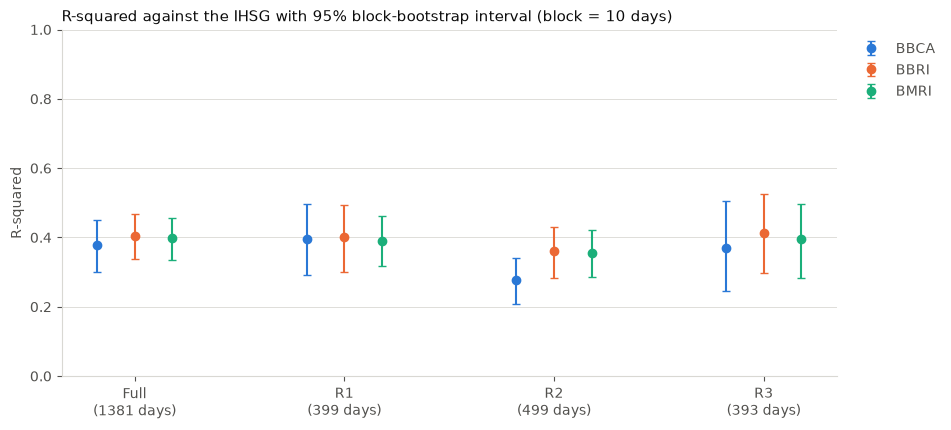

In [13]:
ident = {(p, t): metrics.r2_from_indices(excess.loc[period_days[p], t], excess.loc[period_days[p], MARKET],
                                          np.arange(len(period_days[p]))[None, :])[0] for p in PERIODS for t in BANKS}
d_ident = max(abs(ident[k] - capm_table.loc[k, "r2"]) for k in ident)
check("bootstrap R-squared on the original order equals the regression R-squared", d_ident < 1e-12, f"max abs diff {d_ident:.2e}")

in_range = all(((0 <= v) & (v <= 1)).all() for v in boot.values())
centred = all(abs(np.median(boot[(BLOCK, p, t)]) - capm_table.loc[(p, t), "r2"]) < 0.03 for p in PERIODS for t in BANKS)
check("bootstrap R-squared replicates lie in [0, 1] and are centred near the estimate", in_range and centred)

idx_again = metrics.stationary_bootstrap_indices(len(period_days["R1"]), N_BOOT, BLOCK, SEED + PERIODS.index("R1"))
again = metrics.r2_from_indices(excess.loc[period_days["R1"], "BBCA"], excess.loc[period_days["R1"], MARKET], idx_again)
check("bootstrap is reproducible with the fixed seed", np.array_equal(again, boot[(BLOCK, "R1", "BBCA")]))

fig, ax = plt.subplots(figsize=(10, 4.5))
dot_whisker(ax, r2_ci, "r2", f"ci_low_b{BLOCK}", f"ci_high_b{BLOCK}")
ax.set_ylim(0, 1)
tidy(ax, "R-squared against the IHSG with 95% block-bootstrap interval (block = 10 days)", "R-squared")
legend_outside(ax)
plt.show()

## 6. M8 Dimson beta

If a stock trades less often than the index, its return reacts to the market with a delay and the ordinary beta is biased. The Dimson regression adds the market return one day earlier (`k-1`) and one day later (`k+1`); the Dimson beta is the sum of the three slopes, with an HC3 standard error for the sum. The three banks are very liquid, so a large gap to the ordinary beta is not expected. This is a sensitivity only.

The market shifts are made on the full series first and the regime days are selected afterwards, so a regime's first and last day use the neighbouring day's market return. Only the first and last days of the whole sample lose an observation.

In [14]:
KS = (-1, 0, 1)
shifts = pd.DataFrame({f"k{k:+d}": excess[MARKET].shift(-k) for k in KS})


def dimson_row(period, ticker, days, ks=KS):
    cols = [f"k{k:+d}" for k in ks]
    d = pd.concat([excess.loc[days, ticker].rename("y"), shifts.loc[days, cols]], axis=1).dropna()
    res = sm.OLS(d["y"], sm.add_constant(d[cols])).fit(cov_type="HC3", use_t=True)
    total = np.zeros((1, len(res.params)))
    total[0, 1:] = 1
    tt = res.t_test(total)
    return {
        "period": period, "ticker": ticker, "n": int(res.nobs),
        "dimson_beta": float(res.params[cols].sum()), "dimson_se": float(np.squeeze(tt.sd)),
        **{f"slope_{c}": res.params[c] for c in cols},
    }


dimson = pd.DataFrame([dimson_row(p, t, period_days[p]) for p in PERIODS for t in BANKS]).set_index(["period", "ticker"])
dimson["capm_beta"] = capm_table["beta"]
dimson["diff"] = dimson["dimson_beta"] - dimson["capm_beta"]
dimson.round(4)

n  dimson_beta  dimson_se  slope_k-1  slope_k+0  slope_k+1  capm_beta    diff
period ticker                                                                                  
Full   BBCA    1379       0.9213     0.0907    -0.0262     0.9377     0.0098     0.9365 -0.0152
       BBRI    1379       1.0925     0.0811    -0.0456     1.1390    -0.0009     1.1404 -0.0479
       BMRI    1379       1.1164     0.0903    -0.0809     1.1692     0.0281     1.1693 -0.0529
R1     BBCA     398       0.8485     0.1449    -0.1011     1.0563    -0.1066     1.0566 -0.2081
       BBRI     398       1.2769     0.1605    -0.1035     1.3322     0.0481     1.3380 -0.0611
       BMRI     398       1.1059     0.2010    -0.0990     1.3083    -0.1033     1.3168 -0.2109
R2     BBCA     499       0.9468     0.1384    -0.0868     0.9540     0.0796     0.9550 -0.0082
       BBRI     499       1.4727     0.1604    -0.0218     1.3667     0.1278     1.3557  0.1170
       BMRI     499       1.2456     0.2025    -0.1385     1.4258    -0.0417     1.4452 -0.1995
R3     BBCA     393       0.7070     0.1172    -0.1291     0.8275     0.0087     0.8242 -0.1171
       BBRI     393       0.9509     0.1367    -0.0971     1.0403     0.0077     1.0379 -0.0870
       BMRI     393       1.1002     0.1451    -0.0836     1.0581     0.1257     1.0598  0.0405

In [15]:
only0 = pd.DataFrame([dimson_row(p, t, period_days[p], ks=(0,)) for p in PERIODS for t in BANKS]).set_index(["period", "ticker"])
check("Dimson with only k = 0 reproduces the CAPM beta", (only0["dimson_beta"] - capm_table["beta"]).abs().max() < 1e-12)

fun_d = {t: metrics.dimson_beta(excess[t], excess[MARKET])["beta"] for t in BANKS}
check("Dimson helper equals metrics.dimson_beta (full period)",
      all(abs(dimson.loc[("Full", t), "dimson_beta"] - fun_d[t]) < 1e-12 for t in BANKS))
check("Dimson loses only the first and last day of the sample", (dimson.loc["Full", "n"] == EXPECTED_DAYS - 2).all())

PASS  Dimson with only k = 0 reproduces the CAPM beta
PASS  Dimson helper equals metrics.dimson_beta (full period)
PASS  Dimson loses only the first and last day of the sample


## 7. Sensitivity: without the market-wide shock days

The same regressions after removing the days on which at least three of the four instruments moved by more than 5% (the days listed below). These are the days most likely to pull the estimates. `d_beta` and `d_r2` are the change relative to the main results above. Large changes would mean the betas depend on a handful of extreme days.

In [16]:
drop_days = ret.index[cluster]
print("removed days:", ", ".join(d.strftime("%Y-%m-%d") for d in drop_days))

rows = []
for period in PERIODS:
    days = period_days[period].difference(drop_days)
    for t in BANKS:
        res = fit_capm(excess.loc[days, t], excess.loc[days, MARKET])
        h1 = res.t_test("mkt = 1")
        rows.append({
            "period": period, "ticker": t, "n": int(res.nobs), "days_removed": len(period_days[period]) - len(days),
            "beta": res.params["mkt"], "beta_se": res.bse["mkt"], "p_vs_1": float(np.squeeze(h1.pvalue)), "r2": res.rsquared,
        })
sens = pd.DataFrame(rows).set_index(["period", "ticker"])
sens["d_beta"] = sens["beta"] - capm_table["beta"]
sens["d_r2"] = sens["r2"] - capm_table["r2"]
sens.round(4)

removed days: 2022-05-09, 2025-03-26, 2025-04-08, 2025-10-20, 2026-01-28, 2026-06-09


n  days_removed    beta  beta_se  p_vs_1      r2  d_beta    d_r2
period ticker                                                                     
Full   BBCA    1375             6  0.9181   0.0531  0.1237  0.3352 -0.0184 -0.0417
       BBRI    1375             6  1.1385   0.0538  0.0101  0.3692 -0.0019 -0.0354
       BMRI    1375             6  1.1499   0.0546  0.0062  0.3573 -0.0195 -0.0400
R1     BBCA     398             1  1.0284   0.0891  0.7500  0.3680 -0.0282 -0.0271
       BBRI     398             1  1.3214   0.0944  0.0007  0.3804 -0.0166 -0.0217
       BMRI     398             1  1.2980   0.1026  0.0039  0.3687 -0.0188 -0.0223
R2     BBCA     499             0  0.9550   0.0774  0.5616  0.2763  0.0000  0.0000
       BBRI     499             0  1.3557   0.0933  0.0002  0.3597  0.0000  0.0000
       BMRI     499             0  1.4452   0.1052  0.0000  0.3564  0.0000  0.0000
R3     BBCA     389             4  0.7623   0.0894  0.0081  0.2940 -0.0618 -0.0751
       BBRI     389             4  1.0127   0.0976  0.8962  0.3549 -0.0252 -0.0586
       BMRI     389             4  1.0227   0.0951  0.8119  0.3376 -0.0371 -0.0568

In [17]:
check("the sensitivity removes exactly the shock days", sens.loc["Full", "days_removed"].eq(int(cluster.sum())).all(),
      f"{int(cluster.sum())} days")

PASS  the sensitivity removes exactly the shock days  [6 days]


## 8. Summary and saved tables

Every check above must print PASS. The tables are saved to `reports/` for the report and the later Tableau cross-check.

In [18]:
out = ROOT / "reports"
out.mkdir(exist_ok=True)
capm_table.to_csv(out / "03_capm_regression.csv")
r2_ci.to_csv(out / "03_r2_bootstrap.csv")
r2_diff.to_csv(out / "03_r2_differences.csv")
dimson.to_csv(out / "03_dimson_beta.csv")
sens.to_csv(out / "03_capm_sensitivity.csv")
hac.to_csv(out / "03_capm_hac.csv")

n_fail = results.count(False)
print(f"{len(results) - n_fail} passed, {n_fail} failed")
assert n_fail == 0, "At least one check failed. Investigate before using these tables."

18 passed, 0 failed
